# Abstract #

# I. Introduction #

# II. Data Exploration and Preprocessing #

> **Objective**: This notebook introduces the initial Exploratory Data Analysis (EDA) process that was conducted, as well as the steps taken to clean and prepare the data for genre classification.

## Exploring the Data ##

> This first section will focus on the understanding of the data provided in order to get a global overview of it while also identifying potential patterns, imbalances or other factos that may influence the classification task at hand.

**Step 1:** Importing the necessary libraries and the datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
train_data = pd.read_csv("data/train.csv")
test_data = pd.read_csv("data/test.csv")

In [3]:
train_data.head()

,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050


**Step 2**: Understanding the structure of the dataset.

In [4]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   title     134965 non-null  str  
 1   tag       134967 non-null  str  
 2   artist    134967 non-null  str  
 3   year      134967 non-null  int64
 4   views     134967 non-null  int64
 5   features  134967 non-null  str  
 6   lyrics    134967 non-null  str  
 7   id        134967 non-null  int64
dtypes: int64(3), str(5)
memory usage: 8.2 MB


The training dataset is composed by 134967 songs and 8 attributes, as follows: 

| Attribute | Description |
| :-------- | :---------: |
| `id` | Unique identifier of a song|
| `title` | Title of a song |
| `artist` | Main Artist |
| `year` | Release Year |
| `views` | Number of Online Views |
| `features` | Collaborating Artists |
| `lyrics` | Lyrics of a song |
| `tag` | Musical Genre |

There are two numerical features (excluding the `ìd`) and five categorical features. In the context of this project, `tag` will represent the target variable and `lyrics` the input for this text classification task.
Therefore, altough the remaining attributes still provide descriptive information about each song (and will be important on the **Sentiment Analysis** section of this project), they will not be used for modelling.


An initial inspection of the dataset reveals 2 missing values in the `title` column, whereas the other features seem to be complete.

The training dataset will be used to develop the models that will classify the songs into genres, and will be later split into `train` and `validation`, in order to create a validation dataset that will help evaluate and compare the model's performance on unseen data. The final model will then be applied to the `test` set, that contains the same attributes as the training dataset but without the labels (those will be predicted by the model).

**Step 3**: Checking for duplicate `id`s.

In [5]:
train_data['id'].is_unique

True

There are no duplicates on the `id` column. Therefore, it can be set as the index of our dataframe.

In [6]:
train_data.set_index('id', inplace = True)

In [7]:
train_data.head()

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...


**Step 4**: Checking for duplicate songs on the dataset (same `title` and same `artist`).

**NOTE**: Songs with the same title will not be considered duplicates if they are performed by different artists.

In [8]:
bool(train_data.duplicated(subset=['title', 'artist']).any())

False

**Step 5**: Analysing the target variable (`tag`).

tag
pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: count, dtype: int64

tag
pop        41.300466
rap        28.587729
rock       18.769032
rb          4.595938
misc        4.178799
country     2.568035
Name: proportion, dtype: float64

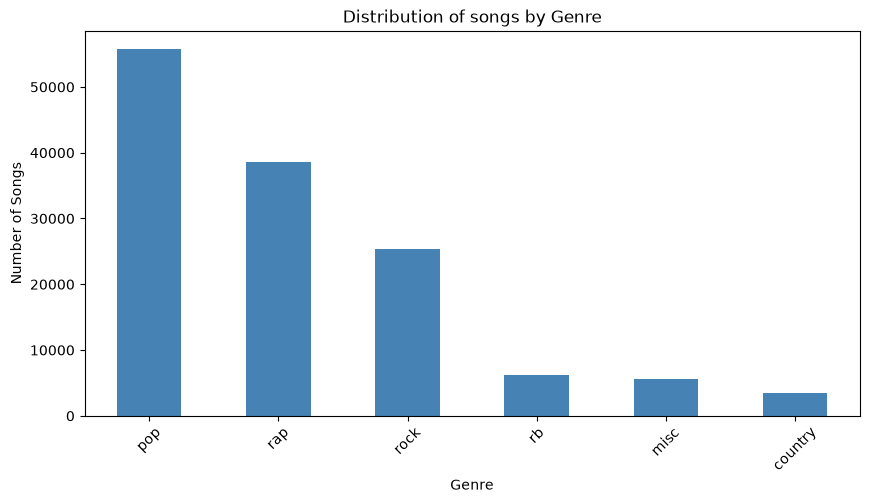

In [9]:
tag_counts = train_data['tag'].value_counts()

display(tag_counts)
display(train_data['tag'].value_counts(normalize = True) * 100)

tag_counts.plot(kind = 'bar', figsize = (10,5), color = 'steelblue')

plt.xlabel('Genre')
plt.ylabel('Number of Songs')
plt.title('Distribution of songs by Genre')

plt.xticks(rotation = 45)
plt.show()

By analysing the ouput, we can see that the songs can be classified into **6** genres: **pop**, **rap**, **rock**, **R&B (rb)**, **miscellaneous (misc)** and **country**. The distribution of this genres across the dataset is imbalanced, with **pop** being the **most** frequent genre (41.3 %) and **country** the **least** frequent (only 2.57%). It is important to acknowledge this imbalance when dealing with a text classification task since the model might become biased towards the more representative class and fail to classify correctly the minority class. Therefore, the model evaluation process should consider metrics like the macro F1-score, instead of simply using the accuracy, to correctly assess performance across all genres.

**Step 6**: Analysing the numerical features.

In [10]:
train_data.describe()

,year,views
count,134967.000000,1.349670e+05
mean,2009.467537,3.413344e+03
std,46.287743,4.192449e+04
min,1.000000,0.000000e+00
25%,2008.000000,2.200000e+01
50%,2015.000000,8.900000e+01
75%,2019.000000,4.730000e+02
max,2024.000000,3.604497e+06


We can observe that the variable `year` has some invalid release years (the minimum value in the dataset is 1). However, we will not spend time cleaning this column as it will not be used in the project.

**Step 7**: Removing the `year` column.

**NOTE**: For the purpose of this project, this variable will not be needed: the **Genre Identification** will be done purely by analysing the lyrics and the **Sentiment Analysis** section will not involve any information regarding the release years of the songs.

In [11]:
train_data = train_data.drop(columns = ['year'])

**Step 8**: Analysing the `views` feature.

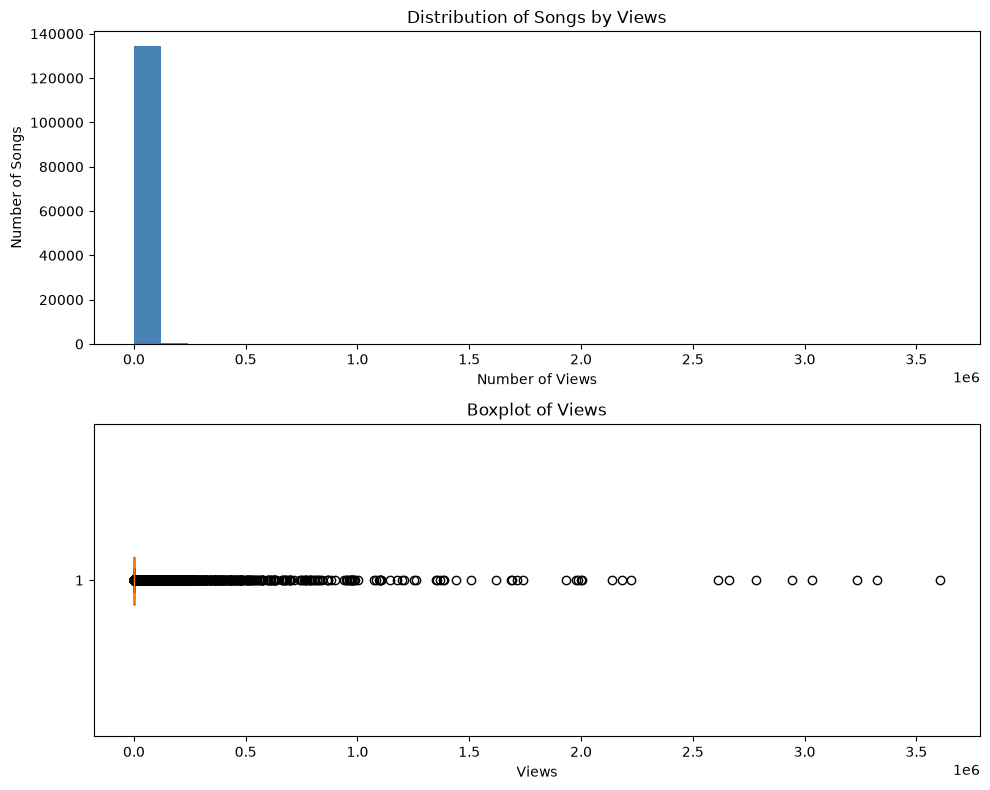

In [12]:
fig, axes = plt.subplots(2, 1, figsize = (10,8))

axes[0].hist(train_data['views'], bins = 30, color = 'steelblue')
axes[0].set_xlabel('Number of Views')
axes[0].set_ylabel('Number of Songs')
axes[0].set_title('Distribution of Songs by Views')

axes[1].boxplot(train_data['views'], vert = False)
axes[1].set_xlabel('Views')
axes[1].set_title('Boxplot of Views')

plt.tight_layout()
plt.show()

As observed in the plot, `views` has a highly right-skewed distribution, with most songs having a low view count and a few of them having a higher count (representing "hits" and high-performing tracks). To better visualize the distribution and understand the underlying pattern, we will apply a logarithmic transformation and replot the variable.

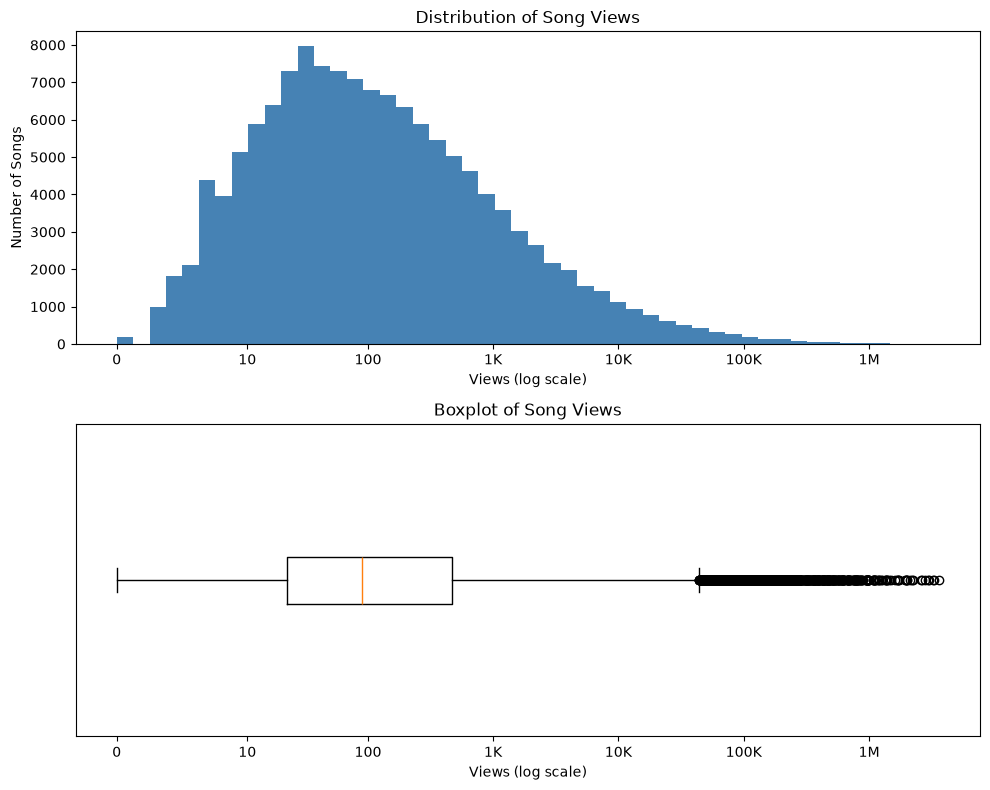

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# log1p instead of log bc there are songs with 0 views
axes[0].hist(np.log1p(train_data['views']), bins=50, color='steelblue') 
axes[0].set_title('Distribution of Song Views')
axes[0].set_xlabel('Views (log scale)')
axes[0].set_ylabel('Number of Songs')

axes[1].boxplot(np.log1p(train_data['views']), vert = False)
axes[1].set_title('Boxplot of Song Views')
axes[1].set_xlabel('Views (log scale)')
axes[1].set_yticks([]) # this removes the '1' on the y-axis

# this code puts back the original values on the labels to be easier to understand
tick_values = np.array([0, 10, 100, 1_000, 10_000, 100_000, 1_000_000])
tick_positions = np.log1p(tick_values)
tick_labels = ['0', '10', '100', '1K', '10K', '100K', '1M']
for ax in axes: 
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

plt.tight_layout()
plt.show()

As we can see, even by apllying the logarithmic transformation, the song views's distribution continues to have a right-tail. The median song has only 89 views, while the maximum is around 3.6 million and the mean (3400) is much higher than the median value. 

**Step 9**: Analysing the categorical variables.

In [14]:
train_data.describe(include='O')

,title,tag,artist,features,lyrics
count,134965,134967,134967,134967,134967
unique,107703,6,74916,18389,134789
top,Intro,pop,Genius English Translations,{},Tell us that you would like to have the lyrics...
freq,135,55742,555,111928,8


As we can see on the `features` variable, the most common value is {}, which is clearly a placeholder for no collaborating artists. However, we will not spend time dealing with this issue as this variable will not be used for the project.

**Step 10**: Removing the features column.

**NOTE**: For the purpose of this project, this variable will not be needed since the **Genre Identification** will be done purely by analysing the lyrics and the **Sentiment Analysis** section will not involve any information regarding collaborating artists, only main ones.

In [15]:
train_data = train_data.drop(columns = ['features'])

**Step 11**: Searching for duplicated lyrics.

In [16]:
duplicated_lyrics = train_data[train_data.duplicated( subset = ['lyrics'], keep = False)].sort_values(by = 'lyrics')

display(duplicated_lyrics[['title', 'artist', 'tag', 'lyrics']])

,title,artist,tag,lyrics
id,,,,
1442530,Damage Ive Done Moby Sad Gospel mix,The Heads,pop,"""There's buzzin' and ringin' in my ear\nAnd I ..."
1214596,Damage Ive Done Sound/Bisquit vocal mix,The Heads,pop,"""There's buzzin' and ringin' in my ear\nAnd I ..."
518757,Phillis Wheatley’s “On Being Brought from Afri...,ChrisApap,misc,"'Twas mercy brought me from my Pagan land,\nTa..."
365464,Phillis Wheatley’s “On Being Brought from Afri...,Dr. Katy Evans,misc,"'Twas mercy brought me from my Pagan land,\nTa..."
3767965,Fingertips Part 1 Second Pressing,Stevie Wonder,rb,"'Yeah'\n'Yeah'\n\nLadies and gentlemen, now I'..."
...,...,...,...,...
711378,Before Its Over,Sixx:A.M.,rock,[Verse 1]\nWell the rain outside is pouring do...
4630228,Twang,Mason Ramsey,country,"[Verse 1]\nYeah, she likes how sweet I like my..."
6155184,Twang,Primrose Ripper,pop,"[Verse 1]\nYeah, she likes how sweet I like my..."


As we can see, most duplicated lyrics have the same genre (same `tag`), while others have two conflicting labels. The approach used here is to keep the first occurence of the lyrics, with the associated genre.

In [17]:
train_data = train_data.drop_duplicates(subset='lyrics', keep='first')

**Step 12**: Analysing the lenght of the lyrics.

In [18]:
train_data['lyric_length'] = train_data['lyrics'].str.split().str.len()

count    134789.000000
mean        317.616786
std         451.534676
min           1.000000
25%         159.000000
50%         244.000000
75%         377.000000
max       18221.000000
Name: lyric_length, dtype: float64

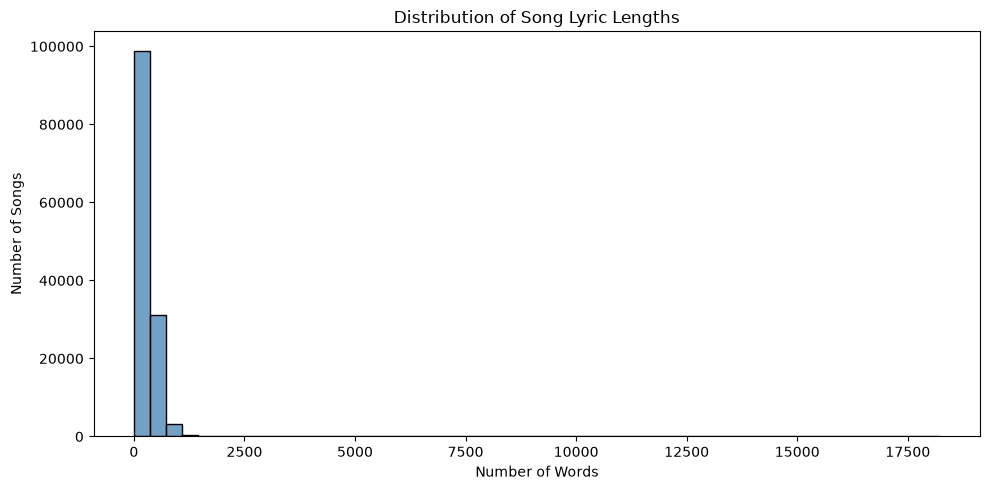

In [19]:
display(train_data['lyric_length'].describe())

plt.figure(figsize = (10, 5))

sns.histplot(train_data, x = 'lyric_length', bins = 50, color = 'steelblue')

plt.title('Distribution of Song Lyric Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Songs')

plt.tight_layout()
plt.show()

The distribution of lyric lenghts is highly right-skewed, with the vast majority of song lyrics having less than 400 words, with the maximum reaching around 18000 words. Most songs are compressed on the first few bins, so we will apply a logarithmic transformation to better visualize them.

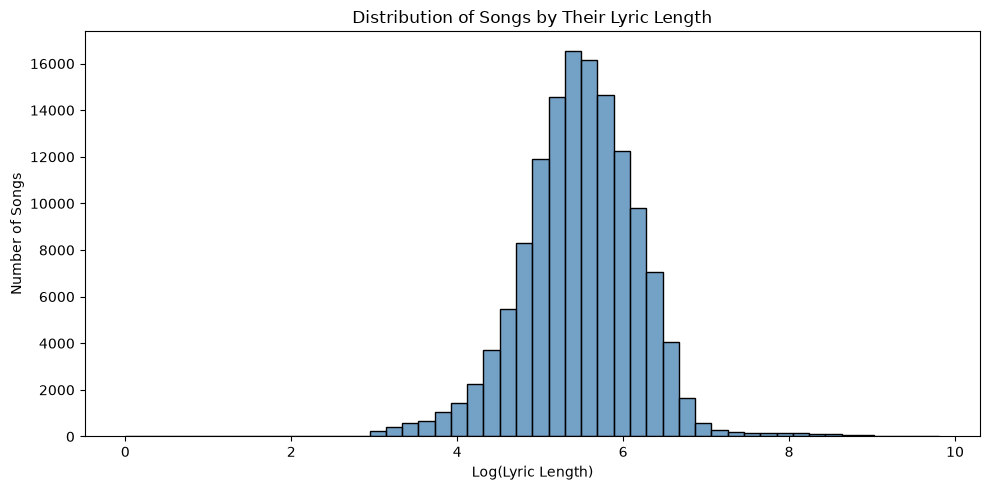

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(np.log(train_data['lyric_length']), bins=50, color='steelblue', ax=ax)

ax.set_title("Distribution of Songs by Their Lyric Length")
ax.set_xlabel('Log(Lyric Length)')
ax.set_ylabel('Number of Songs')

plt.tight_layout()
plt.show()

After the transformation, the distribution becomes more symmetric and bell-shaped. However, as seen before, there is a song with a `lyric_lenght` of 1. Let's analyse it.

In [21]:
train_data[train_data['lyric_length'] == 1]['lyrics']

id
384771    http://www.theatlantic.com/business/archive/20...
Name: lyrics, dtype: str

As we can see, the lyrics above are not even lyrics. This is a URL. As such, it is necessary to investigate the lyrics for more unwanted patterns and to clean them completely.

## Lyrics Cleaning ##

Since the dataset contains observations that are not actually songs, we need to define a way to pin-point them.

Rules to correctly remove non-songs from the dataset:

In [22]:
from utils import contains_lyrics

train_data['contains_lyrics'] = train_data['lyrics'].apply(contains_lyrics)

print(f"Number of observations that are clearly songs: {train_data['contains_lyrics'].sum()}")

Number of observations that are clearly songs: 71522


**Step 13**: Taking a sample of 5 lyrics from the dataset to see that kind of issues we need to solve.

In [22]:
sample_of_5 = train_data['lyrics'].sample(5)

for sample in sample_of_5:
    print(repr(sample)) # repr() is a literal representation of the lyrics

'Thunderous beats shake the ground underneath\nHundreds of feet that jump and leap and thump drunkenly\nBeneath the trunks of people who’ve all come to see\nSomeone unbelievable, with a tongue to speak\nWith two lungs to breathe and a mind composed\nTo rhyme blindfolded on high vinyl ropes\nAnd drive winding roads disinclined to doze\nI won’t let my eyes close ‘til it’s my time to go\nAs I find the signposts to keep me oriented\nTo keep me soaring into the morning with no resentment\nTo give me more incentive to get my stories printed\nIgnoring poor intentions until this party’s ended\nI’m sorry if you’re offended; just count to ten\nAnd then bounce around when the record sound spins\nI’m out to move mountains with a fountain pen\nAnd then step down proudly in the crowd and grin\nI’ve been around the bend, and I’m trying to make it back\nTo the only place I have where I’m still safe at last\nAs I trace my path through this race of rats\nAll I taste is ashtrays, waste and trash\nEvery p

Some issues that we can identify are:
- **inconsistent apostrophes**: "They´re" instead of "They're"
- **structural annotations**: [Verse 1], [Chorus]
- **URLs and newlines**

**Step 14**: Checking how many songs have emojis, handles (@), hastags (#), URLs and newlines in the lyrics.

In [ ]:
from utils import (
    contains_emoji,
    contains_handle,
    contains_hastag,
    contains_url,
    contains_newline,
    contains_html
)

train_data['has_emoji'] = train_data['lyrics'].apply(contains_emoji)
train_data['has_handle'] = train_data['lyrics'].apply(contains_handle)
train_data['has_hastag'] = train_data['lyrics'].apply(contains_hastag)
train_data['has_url'] = train_data['lyrics'].apply(contains_url)
train_data['has_newline'] = train_data['lyrics'].apply(contains_newline)
train_data['has_html'] = train_data['lyrics'].apply(contains_html)

patterns = train_data[['has_emoji', 'has_handle', 'has_hastag', 'has_url', 'has_newline']].sum().rename_axis('Pattern').reset_index(name = 'Number of Songs')

display(patterns)

,Pattern,Number of Songs
0,has_emoji,46
1,has_handle,79
2,has_hastag,337
3,has_url,169
4,has_newline,133959


As expected, most of the songs have newlines.

**Step 15**: Extracting one example of each pattern.

In [ ]:
emoji_example = train_data.loc[train_data['has_emoji'], 'lyrics'].iloc[0]
handle_example = train_data.loc[train_data['has_handle'], 'lyrics'].iloc[0]
hashtag_example = train_data.loc[train_data['has_hastag'], 'lyrics'].iloc[0]
url_example = train_data.loc[train_data['has_url'], 'lyrics'].iloc[0]
newline_example = train_data.loc[train_data['has_newline'], 'lyrics'].iloc[0]
html_example = train_data.loc[train_data['has_html'], 'lyrics'].iloc[0]

print("emoji example:\n", repr(emoji_example))
print("\nhandle example:\n", repr(handle_example))
print("\nhastag example:\n", repr(hashtag_example))
print("\nurl example:\n", repr(url_example))
print("\nnewline example:\n", repr(newline_example))

emoji example:
 "In the field of economics, the commodity value of a good is its free market intrinsic value under optimal use conditions. In a free market, the commodity value of a good will be reflected by its price. For example, if an acre of land can yield a net of 100 dollars loss by lying fallow, 50 dollars gain by being planted with corn, and 100 dollars gain by being planted with wheat, then that acre's commodity value is 100 dollars; the farmer is assumed to put his land to best use.\n\nCURRENCY:\nCommodity value is of particular significance in the study of currency. For example, the commodity value of a coin is the value of the metal of which it is made. Gold and silver coins have a high commodity value, whereas fiat coins such as modern day quarters have a low commodity value. This is of particular historical relevance when analyzed in light of Gresham's Law.\n\n....__◥███◣\n╱◥◣ ◥████◣\n│╱◥█◣║∩©∩║\n││☊.│ ▓ ║∩田 ║ **Suite2**\nAsset backed debt has a commodity value equal to t